# Streamlit App: Bank Customer Churn Risk Dashboard

A Streamlit app runs in the browser, not inside a notebook cell. This notebook therefore does three things:

1. **Writes** the app files (`streamlit_app.py`, `requirements.txt`) from the cells below
2. **Previews** each app module here in the notebook (risk calculator, distribution, feature importance, what-if)
3. **Launches** the app so you can open it in your browser

| App module | Brief requirement |
|---|---|
| Risk calculator | Customer churn risk calculator |
| Probability distribution | Probability distribution visualization |
| Feature importance | Feature importance dashboard |
| What-if simulator | What-if scenario simulator |

**Before you start:** the app needs the `artifacts/` folder created by the modeling notebook (`Bank_Churn_Prediction.ipynb`) or by `churn_model.py`. Keep it in the same folder as this notebook.

## 1. Install requirements

In [1]:
# Run once. Pin scikit-learn to the version you trained the model with.
%pip install -q streamlit plotly pandas numpy joblib scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Locate the model files

The app needs a folder called `artifacts/` next to this notebook. This cell checks the current folder, looks in nearby folders if it is missing, and copies it here if it finds one. If it finds nothing, it stops with a clear message.

In [2]:
import os
import shutil
from pathlib import Path

needed = ["churn_pipeline.joblib", "metadata.json", "test_scores.csv",
          "feature_importance.csv", "model_comparison.csv"]


def has_all(folder):
    return folder.is_dir() and all((folder / f).exists() for f in needed)


print("Notebook is running from:", Path.cwd())
ART = Path("artifacts")

if not has_all(ART):
    here = Path.cwd().resolve()
    search_roots = [here, *list(here.parents)[:3]]
    found = None
    for root in search_roots:
        # look for an artifacts folder in this folder, then one and two levels below it
        for pattern in ["artifacts", "*/artifacts", "*/*/artifacts"]:
            for cand in root.glob(pattern):
                if has_all(cand):
                    found = cand
                    break
            if found:
                break
        if found:
            break
    if found:
        shutil.copytree(found, ART, dirs_exist_ok=True)
        print(f"Found model files in {found} and copied them to {ART.resolve()}")
    else:
        raise FileNotFoundError(
            "No complete 'artifacts' folder found. Run Bank_Churn_Prediction.ipynb "
            "(or: python churn_model.py) first. It creates the folder with: " + ", ".join(needed))

print("All model files found in", ART.resolve())

Notebook is running from: c:\Users\NAINA\OneDrive\Documents\GitHub\Data_Analysis_Internship_Projects\Data_Analysis_Internship_Projects\Predictive Modeling and Risk Scoring for Bank Customer Churn\App
All model files found in C:\Users\NAINA\OneDrive\Documents\GitHub\Data_Analysis_Internship_Projects\Data_Analysis_Internship_Projects\Predictive Modeling and Risk Scoring for Bank Customer Churn\App\artifacts


## 3. Write the app file

The cell below saves the full Streamlit app as `streamlit_app.py`. This is the file you push to GitHub and deploy.

In [3]:
%%writefile streamlit_app.py
"""
Bank Customer Churn Risk Dashboard (Streamlit)
==============================================
Modules: churn risk calculator, probability distribution, feature importance
dashboard, what-if scenario simulator, model and methodology notes.

Needs the ./artifacts/ folder produced by churn_model.py (or the notebook):
    churn_pipeline.joblib, metadata.json, test_scores.csv,
    feature_importance.csv, model_comparison.csv  (+ optional PNG plots)

Run locally:
    streamlit run app.py
"""

import hashlib
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

ART = Path(__file__).parent / "artifacts"
RAW_FEATURES = [
    "CreditScore", "Geography", "Gender", "Age", "Tenure", "Balance",
    "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary",
]

st.set_page_config(page_title="Bank Churn Risk Dashboard", page_icon="🏦", layout="wide")


# --------------------------------------------------------------------------
# Model logic (same feature engineering as training)
# --------------------------------------------------------------------------
def add_features(df):
    out = df.copy()
    out["BalanceSalaryRatio"] = out["Balance"] / (out["EstimatedSalary"] + 1)
    out["ProductDensity"] = out["NumOfProducts"] / (out["Tenure"] + 1)
    out["ActiveXProducts"] = out["IsActiveMember"] * out["NumOfProducts"]
    out["AgeXTenure"] = out["Age"] * out["Tenure"]
    out["ZeroBalance"] = (out["Balance"] == 0).astype(int)
    return out


def to_frame(customers):
    """List of dicts -> DataFrame with the dtypes the model was trained on."""
    df = pd.DataFrame(customers)[RAW_FEATURES]
    for c in ["CreditScore", "Age", "Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember"]:
        df[c] = df[c].astype(int)
    for c in ["Balance", "EstimatedSalary"]:
        df[c] = df[c].astype(float)
    return df


def predict(pipe, customers):
    return pipe.predict_proba(add_features(to_frame(customers)))[:, 1]


def risk_band(p, bands):
    if p < bands[0]:
        return "Low"
    if p < bands[1]:
        return "Medium"
    return "High"


BAND_COLOR = {"Low": "#2E8B57", "Medium": "#E0A100", "High": "#C0392B"}


@st.cache_resource
def load_artifacts():
    pipe = joblib.load(ART / "churn_pipeline.joblib")
    meta = json.loads((ART / "metadata.json").read_text())
    scores = pd.read_csv(ART / "test_scores.csv")
    imp = pd.read_csv(ART / "feature_importance.csv")
    comp = pd.read_csv(ART / "model_comparison.csv")
    return pipe, meta, scores, imp, comp


if not (ART / "churn_pipeline.joblib").exists():
    st.error("Model files not found. Run `python churn_model.py` (or the notebook) first "
             "so that the `artifacts/` folder exists next to app.py.")
    st.stop()

pipe, meta, scores, imp, comp = load_artifacts()
THRESHOLD = meta["threshold"]
BANDS = tuple(meta["risk_bands"])
RNG = meta["feature_ranges"]

# --------------------------------------------------------------------------
# Sidebar: customer inputs
# --------------------------------------------------------------------------
st.sidebar.header("Customer profile")
cs = st.sidebar.slider("Credit score", int(RNG["CreditScore"][0]), int(RNG["CreditScore"][1]), 650)
geo = st.sidebar.selectbox("Geography", meta["geographies"])
gender = st.sidebar.selectbox("Gender", meta["genders"])
age = st.sidebar.slider("Age", int(RNG["Age"][0]), int(RNG["Age"][1]), 40)
tenure = st.sidebar.slider("Tenure (years with bank)", int(RNG["Tenure"][0]), int(RNG["Tenure"][1]), 5)
balance = st.sidebar.number_input("Account balance", 0.0, float(np.ceil(RNG["Balance"][1] / 1000) * 1000),
                                  75000.0, step=1000.0)
products = st.sidebar.slider("Number of products", 1, 4, 1)
has_card = st.sidebar.radio("Has credit card", ["Yes", "No"], horizontal=True) == "Yes"
active = st.sidebar.radio("Active member", ["Yes", "No"], horizontal=True) == "Yes"
salary = st.sidebar.number_input("Estimated annual salary", 0.0,
                                 float(np.ceil(RNG["EstimatedSalary"][1] / 1000) * 1000),
                                 80000.0, step=1000.0)

base = {"CreditScore": cs, "Geography": geo, "Gender": gender, "Age": age, "Tenure": tenure,
        "Balance": balance, "NumOfProducts": products, "HasCrCard": int(has_card),
        "IsActiveMember": int(active), "EstimatedSalary": salary}
base_p = float(predict(pipe, [base])[0])
base_band = risk_band(base_p, BANDS)
sig = hashlib.md5(json.dumps(base, sort_keys=True).encode()).hexdigest()[:8]

st.sidebar.markdown("---")
st.sidebar.caption(f"Model: {meta['best_model']}  |  Flag threshold: {THRESHOLD:.2f}  |  "
                   f"Bands: Low < {BANDS[0]:.2f} <= Medium < {BANDS[1]:.2f} <= High")

st.title("Bank Customer Churn Risk Dashboard")
st.caption("Predicts the probability that a customer will leave, so retention teams can act early "
           "and target the right customers.")

tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "Risk calculator", "Probability distribution", "Feature importance",
    "What-if simulator", "Model and method",
])

# --------------------------------------------------------------------------
# Tab 1: risk calculator
# --------------------------------------------------------------------------
with tab1:
    left, right = st.columns([3, 2])
    with left:
        fig = go.Figure(go.Indicator(
            mode="gauge+number",
            value=base_p * 100,
            number={"suffix": "%", "valueformat": ".1f"},
            title={"text": "Churn probability"},
            gauge={
                "axis": {"range": [0, 100]},
                "bar": {"color": "#1F4E79"},
                "steps": [
                    {"range": [0, BANDS[0] * 100], "color": "#CDEBD8"},
                    {"range": [BANDS[0] * 100, BANDS[1] * 100], "color": "#FBE7A8"},
                    {"range": [BANDS[1] * 100, 100], "color": "#F5C6C0"},
                ],
                "threshold": {"line": {"color": "black", "width": 4}, "thickness": 0.8,
                              "value": THRESHOLD * 100},
            },
        ))
        fig.update_layout(height=320, margin=dict(l=20, r=20, t=60, b=10))
        st.plotly_chart(fig, width="stretch")
        st.caption("Black marker = decision threshold used for the churn flag.")
    with right:
        st.metric("Churn probability", f"{base_p:.1%}")
        st.markdown(f"**Risk band:** <span style='color:{BAND_COLOR[base_band]};font-weight:700'>"
                    f"{base_band}</span>", unsafe_allow_html=True)
        flag = base_p >= THRESHOLD
        st.markdown(f"**Churn flag:** {'Likely to churn' if flag else 'Likely to stay'}")
        pct = (scores["ChurnProbability"] < base_p).mean()
        st.markdown(f"**Riskier than {pct:.0%}** of customers in the test set")
        actions = {
            "Low": "Standard engagement. Keep the customer informed about relevant products.",
            "Medium": "Proactive outreach: a personalised offer or a relationship-manager check-in.",
            "High": "Priority retention: call within days with a tailored offer and review their products.",
        }
        st.info(actions[base_band])

    st.subheader("Single-change retention levers")
    levers = []
    if not active:
        levers.append(("Make the customer an active member", {"IsActiveMember": 1}))
    if products != 2:
        levers.append(("Move to 2 products", {"NumOfProducts": 2}))
    if not has_card:
        levers.append(("Add a credit card", {"HasCrCard": 1}))
    if levers:
        cand = [{**base, **chg} for _, chg in levers]
        ps = predict(pipe, cand)
        table = pd.DataFrame({
            "Change": [n for n, _ in levers],
            "New probability": [f"{p:.1%}" for p in ps],
            "Change vs current": [f"{(p - base_p) * 100:+.1f} pts" for p in ps],
        })
        st.dataframe(table, hide_index=True, width="stretch")
        st.caption("These show how the model's score responds to a change. They are associations "
                   "in historical data, not proof that the change causes lower churn.")
    else:
        st.write("This customer is already active, holds 2 products and has a credit card.")

# --------------------------------------------------------------------------
# Tab 2: probability distribution
# --------------------------------------------------------------------------
with tab2:
    st.subheader("Where does this customer sit in the population?")
    df_s = scores.copy()
    df_s["Actual outcome"] = df_s["Exited"].map({0: "Retained", 1: "Churned"})
    fig = px.histogram(df_s, x="ChurnProbability", color="Actual outcome", nbins=40,
                       barmode="overlay", opacity=0.65,
                       color_discrete_map={"Retained": "#4682B4", "Churned": "#CD5C5C"},
                       labels={"ChurnProbability": "Predicted churn probability"})
    fig.add_vline(x=THRESHOLD, line_dash="dash", line_color="black",
                  annotation_text=f"Threshold {THRESHOLD:.2f}", annotation_position="top")
    fig.add_vline(x=base_p, line_color="#1F4E79", line_width=3,
                  annotation_text="This customer", annotation_position="top left")
    fig.update_layout(height=420, yaxis_title="Customers (test set)")
    st.plotly_chart(fig, width="stretch")

    df_s["Band"] = df_s["ChurnProbability"].apply(lambda p: risk_band(p, BANDS))
    summ = (df_s.groupby("Band").agg(Customers=("Exited", "size"), ActualChurnRate=("Exited", "mean"))
            .reindex(["Low", "Medium", "High"]))
    summ["Share of customers"] = (summ["Customers"] / summ["Customers"].sum()).map("{:.1%}".format)
    summ["ActualChurnRate"] = summ["ActualChurnRate"].map("{:.1%}".format)
    st.markdown("**Risk bands on the held-out test set**")
    st.dataframe(summ.rename(columns={"ActualChurnRate": "Actual churn rate"}),
                 width="stretch")
    st.caption("A useful risk score shows actual churn rising from Low to High.")

# --------------------------------------------------------------------------
# Tab 3: feature importance
# --------------------------------------------------------------------------
with tab3:
    st.subheader("What drives churn in this model?")
    top_n = st.slider("Features to show", 5, len(imp), min(12, len(imp)))
    top = imp.head(top_n).iloc[::-1]
    fig = px.bar(top, x="importance_mean", y="feature", orientation="h",
                 error_x="importance_std",
                 labels={"importance_mean": "Drop in ROC-AUC when feature is shuffled",
                         "feature": ""})
    fig.update_traces(marker_color="#1F4E79")
    fig.update_layout(height=max(350, 28 * top_n))
    st.plotly_chart(fig, width="stretch")
    lead = imp.head(3)["feature"].tolist()
    st.markdown(f"The three strongest drivers are **{lead[0]}**, **{lead[1]}** and **{lead[2]}**. "
                "Permutation importance measures how much the model's ranking ability falls when "
                "a feature is shuffled. It shows what the model relies on, not what causes churn.")

    c1, c2 = st.columns(2)
    for col, fname, title in [(c1, "shap_summary.png", "SHAP summary (direction and size of effects)"),
                              (c2, "partial_dependence.png", "Partial dependence (shape of effects)")]:
        if (ART / fname).exists():
            col.markdown(f"**{title}**")
            col.image(str(ART / fname), width="stretch")

# --------------------------------------------------------------------------
# Tab 4: what-if simulator
# --------------------------------------------------------------------------
with tab4:
    st.subheader("What-if scenario simulator")
    st.write("The baseline is the customer in the sidebar. Change the values below to build a "
             "scenario and see how the churn probability moves.")

    c1, c2, c3 = st.columns(3)
    s_prod = c1.slider("Number of products", 1, 4, products, key=f"wi_prod_{sig}")
    s_active = c2.radio("Active member", ["Yes", "No"], index=0 if active else 1,
                        horizontal=True, key=f"wi_act_{sig}") == "Yes"
    s_card = c3.radio("Has credit card", ["Yes", "No"], index=0 if has_card else 1,
                      horizontal=True, key=f"wi_card_{sig}") == "Yes"
    with st.expander("More scenario inputs"):
        e1, e2, e3, e4 = st.columns(4)
        s_bal = e1.number_input("Balance", 0.0, float(np.ceil(RNG["Balance"][1] / 1000) * 1000),
                                float(balance), step=1000.0, key=f"wi_bal_{sig}")
        s_ten = e2.slider("Tenure", int(RNG["Tenure"][0]), int(RNG["Tenure"][1]), tenure,
                          key=f"wi_ten_{sig}")
        s_age = e3.slider("Age", int(RNG["Age"][0]), int(RNG["Age"][1]), age, key=f"wi_age_{sig}")
        s_cs = e4.slider("Credit score", int(RNG["CreditScore"][0]), int(RNG["CreditScore"][1]),
                         cs, key=f"wi_cs_{sig}")

    scen = {**base, "NumOfProducts": s_prod, "IsActiveMember": int(s_active),
            "HasCrCard": int(s_card), "Balance": s_bal, "Tenure": s_ten, "Age": s_age,
            "CreditScore": s_cs}
    scen_p = float(predict(pipe, [scen])[0])
    scen_band = risk_band(scen_p, BANDS)

    m1, m2, m3 = st.columns(3)
    m1.metric("Baseline probability", f"{base_p:.1%}", base_band, delta_color="off")
    m2.metric("Scenario probability", f"{scen_p:.1%}", f"{(scen_p - base_p) * 100:+.1f} pts",
              delta_color="inverse")
    m3.metric("Scenario risk band", scen_band)

    fig = go.Figure(go.Bar(x=["Baseline", "Scenario"], y=[base_p * 100, scen_p * 100],
                           marker_color=[BAND_COLOR[base_band], BAND_COLOR[scen_band]],
                           text=[f"{base_p:.1%}", f"{scen_p:.1%}"], textposition="outside"))
    fig.add_hline(y=THRESHOLD * 100, line_dash="dash", line_color="black",
                  annotation_text="Threshold")
    fig.update_layout(height=320, yaxis=dict(range=[0, 105], title="Churn probability (%)"))
    st.plotly_chart(fig, width="stretch")

    st.markdown("**Sweep one variable** (other scenario inputs held fixed)")
    sweep_var = st.selectbox("Variable", ["Age", "NumOfProducts", "Balance", "Tenure",
                                          "CreditScore", "EstimatedSalary"])
    lo, hi = RNG[sweep_var]
    if sweep_var == "NumOfProducts":
        vals = np.arange(1, 5)
    elif sweep_var in ("Age", "Tenure", "CreditScore"):
        vals = np.unique(np.linspace(lo, hi, 40).round().astype(int))
    else:
        vals = np.linspace(lo, hi, 40)
    ps = predict(pipe, [{**scen, sweep_var: v} for v in vals])
    fig = go.Figure(go.Scatter(x=vals, y=ps * 100, mode="lines+markers", line=dict(color="#1F4E79")))
    fig.add_hline(y=THRESHOLD * 100, line_dash="dash", line_color="black",
                  annotation_text="Threshold")
    fig.update_layout(height=340, xaxis_title=sweep_var, yaxis_title="Churn probability (%)")
    st.plotly_chart(fig, width="stretch")
    if sweep_var == "NumOfProducts":
        st.caption("Only a few customers hold 3 or 4 products, so the model's estimates there "
                   "are less reliable.")

# --------------------------------------------------------------------------
# Tab 5: model and method
# --------------------------------------------------------------------------
with tab5:
    st.subheader("Model performance")
    tm = meta["test_metrics_tuned"]
    dm = meta["test_metrics_default_0.5"]
    cols = st.columns(5)
    for col, key in zip(cols, ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]):
        col.metric(key.replace("_", "-"), f"{tm[key]:.3f}", f"{tm[key] - dm[key]:+.3f} vs 0.50 cut-off",
                   delta_color="off")
    st.caption(f"Held-out test set, threshold {THRESHOLD:.2f}. The threshold was tuned on "
               "out-of-fold training predictions to balance precision and recall.")

    st.markdown("**Model comparison** (ranked by cross-validated ROC-AUC)")
    st.dataframe(comp.round(4), hide_index=True, width="stretch")

    st.subheader("Method in brief")
    st.markdown(
        "- **Data:** European bank customers (10,000 rows). Target: `Exited`.\n"
        "- **Preprocessing:** dropped identifiers and a constant column, one-hot encoded "
        "Geography and Gender, scaled numeric features.\n"
        "- **Engineered features:** balance-to-salary ratio, product density, "
        "engagement-product interaction, age-tenure interaction, zero-balance flag.\n"
        "- **Validation:** stratified train/test split and 5-fold stratified cross-validation. "
        "The test set was used once for reporting.\n"
        "- **Explainability:** permutation importance, partial dependence and SHAP.")

    st.subheader("Limitations and responsible use")
    st.markdown(
        "- Based on a single historical snapshot. Behaviour and products change over time, so "
        "the model needs monitoring and periodic retraining.\n"
        "- Scores show association, not cause. Use them to prioritise outreach, not to "
        "make adverse decisions about customers.\n"
        "- Gender and Geography are model inputs. Review the model for fair treatment across "
        "groups before using it to target offers.\n"
        "- Estimates for rare groups (for example 3 or 4 products) are less stable.")

Overwriting streamlit_app.py


## 4. Write requirements.txt (needed for deployment)

In [4]:
%%writefile requirements.txt
streamlit>=1.50
plotly>=5.20
pandas>=2.0
numpy>=1.26
joblib>=1.3
xgboost>=2.0
# IMPORTANT: pin scikit-learn to the exact version you trained the model with,
# otherwise the saved model may fail to load. Check it with:
#   python -c "import sklearn; print(sklearn.__version__)"
# then replace the line below, for example: scikit-learn==1.5.2
scikit-learn

Overwriting requirements.txt


## 5. Preview the app modules in the notebook

These cells reproduce what each tab of the app shows, using the same model and logic, so you can check the numbers before launching.

In [5]:
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pipe = joblib.load(ART / "churn_pipeline.joblib")
meta = json.loads((ART / "metadata.json").read_text())
scores = pd.read_csv(ART / "test_scores.csv")
imp = pd.read_csv(ART / "feature_importance.csv")
comp = pd.read_csv(ART / "model_comparison.csv")

THRESHOLD = meta["threshold"]
BANDS = tuple(meta["risk_bands"])
RAW = meta["raw_features"]


def add_features(df):
    out = df.copy()
    out["BalanceSalaryRatio"] = out["Balance"] / (out["EstimatedSalary"] + 1)
    out["ProductDensity"] = out["NumOfProducts"] / (out["Tenure"] + 1)
    out["ActiveXProducts"] = out["IsActiveMember"] * out["NumOfProducts"]
    out["AgeXTenure"] = out["Age"] * out["Tenure"]
    out["ZeroBalance"] = (out["Balance"] == 0).astype(int)
    return out


def predict(customers):
    df = pd.DataFrame(customers)[RAW]
    for c in ["CreditScore", "Age", "Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember"]:
        df[c] = df[c].astype(int)
    for c in ["Balance", "EstimatedSalary"]:
        df[c] = df[c].astype(float)
    return pipe.predict_proba(add_features(df))[:, 1]


def risk_band(p):
    return "Low" if p < BANDS[0] else ("Medium" if p < BANDS[1] else "High")


print(f"Model: {meta['best_model']} | threshold {THRESHOLD:.2f} | bands {BANDS}")

Model: Gradient Boosting | threshold 0.30 | bands (0.3, 0.6)


### 5.1 Risk calculator

Churn probability: 90.8% | Risk band: High | Flag: Likely to churn
Riskier than 97% of test-set customers


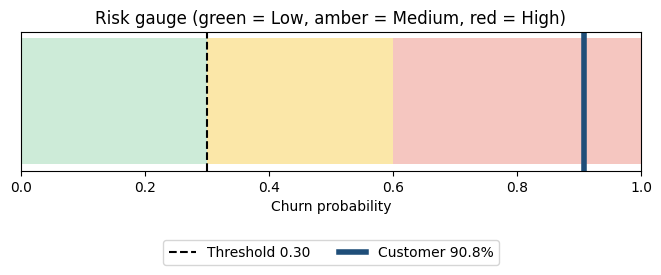

In [6]:
# Edit this customer, as you would in the app sidebar
customer = {"CreditScore": 600, "Geography": "Germany", "Gender": "Female", "Age": 52,
            "Tenure": 3, "Balance": 120000.0, "NumOfProducts": 1, "HasCrCard": 1,
            "IsActiveMember": 0, "EstimatedSalary": 80000.0}

p = float(predict([customer])[0])
print(f"Churn probability: {p:.1%} | Risk band: {risk_band(p)} | "
      f"Flag: {'Likely to churn' if p >= THRESHOLD else 'Likely to stay'}")
print(f"Riskier than {(scores['ChurnProbability'] < p).mean():.0%} of test-set customers")

fig, ax = plt.subplots(figsize=(8, 1.8))
ax.barh([0], [BANDS[0]], color="#CDEBD8")
ax.barh([0], [BANDS[1] - BANDS[0]], left=BANDS[0], color="#FBE7A8")
ax.barh([0], [1 - BANDS[1]], left=BANDS[1], color="#F5C6C0")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"Threshold {THRESHOLD:.2f}")
ax.axvline(p, color="#1F4E79", linewidth=4, label=f"Customer {p:.1%}")
ax.set_xlim(0, 1)
ax.set_yticks([])
ax.set_xlabel("Churn probability")
ax.set_title("Risk gauge (green = Low, amber = Medium, red = High)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2)
plt.show()

### 5.2 Probability distribution

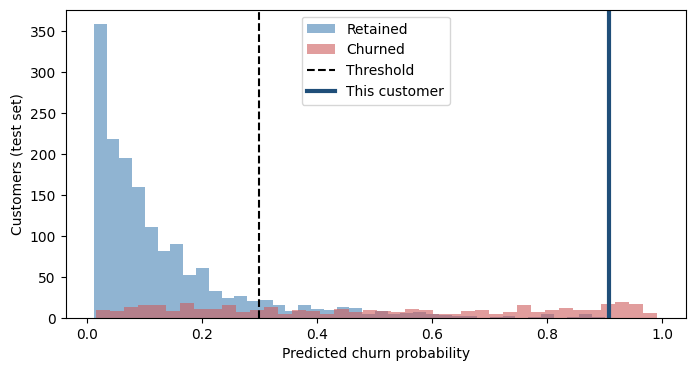

,customers,actual_churn_rate
ChurnProbability,,
Low,1570,8.9
Medium,247,43.7
High,183,87.4


In [7]:
plt.figure(figsize=(8, 4))
plt.hist(scores.loc[scores.Exited == 0, "ChurnProbability"], bins=40, alpha=0.6, label="Retained", color="steelblue")
plt.hist(scores.loc[scores.Exited == 1, "ChurnProbability"], bins=40, alpha=0.6, label="Churned", color="indianred")
plt.axvline(THRESHOLD, color="black", linestyle="--", label="Threshold")
plt.axvline(p, color="#1F4E79", linewidth=3, label="This customer")
plt.xlabel("Predicted churn probability")
plt.ylabel("Customers (test set)")
plt.legend()
plt.show()

bands = scores["ChurnProbability"].apply(risk_band)
summary = scores.groupby(bands).agg(customers=("Exited", "size"), actual_churn_rate=("Exited", "mean"))
summary = summary.reindex(["Low", "Medium", "High"])
summary["actual_churn_rate"] = (summary["actual_churn_rate"] * 100).round(1)
summary

### 5.3 Feature importance

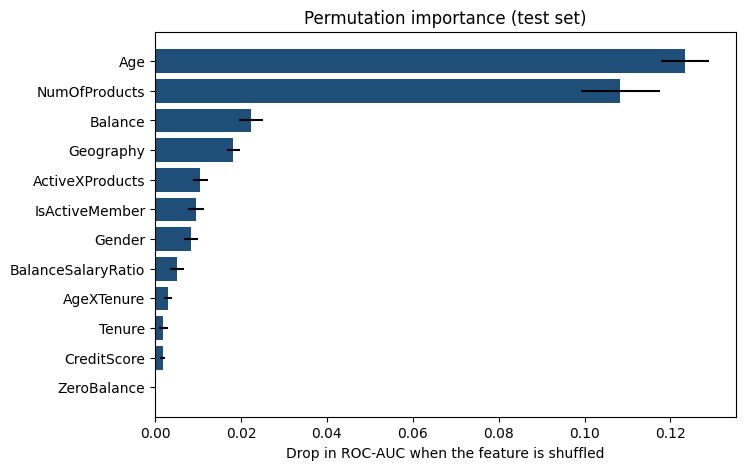

In [8]:
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(7.5, 5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#1F4E79")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.show()

### 5.4 What-if simulator

,Inactive,Active
NumOfProducts,,
1,0.908,0.647
2,0.727,0.364
3,0.969,0.956
4,0.979,0.973


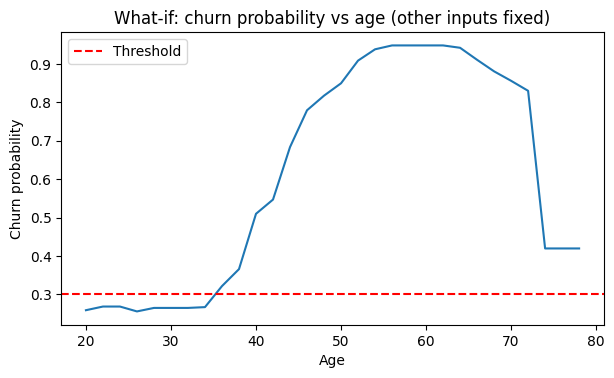

In [9]:
rows = []
for prods in [1, 2, 3, 4]:
    for act in [0, 1]:
        rows.append({"NumOfProducts": prods, "IsActiveMember": act,
                     "ChurnProbability": float(predict([{**customer, "NumOfProducts": prods,
                                                          "IsActiveMember": act}])[0])})
whatif = pd.DataFrame(rows).pivot(index="NumOfProducts", columns="IsActiveMember", values="ChurnProbability")
whatif.columns = ["Inactive", "Active"]
display(whatif.round(3))

ages = np.arange(20, 80, 2)
ps = predict([{**customer, "Age": int(a)} for a in ages])
plt.figure(figsize=(7, 3.8))
plt.plot(ages, ps)
plt.axhline(THRESHOLD, color="red", linestyle="--", label="Threshold")
plt.xlabel("Age")
plt.ylabel("Churn probability")
plt.title("What-if: churn probability vs age (other inputs fixed)")
plt.legend()
plt.show()

## 6. Launch the app

The next cell starts Streamlit in the background and prints the address. Open it in your browser.

- **On your own computer (Jupyter or VS Code):** open **http://localhost:8501**
- **On Google Colab:** localhost is not reachable from your browser. Use the tunnel cell below.

You can also launch it from a terminal instead: `streamlit run streamlit_app.py`

In [10]:
import subprocess, sys, time, urllib.request

PORT = 8501
proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "streamlit_app.py",
     "--server.headless", "true", "--server.port", str(PORT)],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT)

for _ in range(30):
    time.sleep(1)
    try:
        ok = urllib.request.urlopen(f"http://localhost:{PORT}/_stcore/health", timeout=2).read()
        print("Streamlit is running:", ok.decode())
        print(f"Open http://localhost:{PORT} in your browser")
        break
    except Exception:
        continue
else:
    print("App did not start in 30 seconds. Check the messages below.")
    proc.terminate()
    print(proc.stdout.read().decode()[-1500:])

Streamlit is running: ok
Open http://localhost:8501 in your browser


In [11]:
# Google Colab only: expose the app through a temporary public tunnel
import sys
if "google.colab" in sys.modules:
    !npm install -q localtunnel
    import urllib.request
    print("Tunnel password (your public IP):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
    !npx localtunnel --port 8501
else:
    print("Not on Colab. Use http://localhost:8501")

Not on Colab. Use http://localhost:8501


## 7. Stop the app

In [12]:
proc.terminate()
print("Streamlit stopped.")

Streamlit stopped.


## 8. Deploy for your submission link

| Step | Action |
|---|---|
| 1 | Push these to GitHub: `streamlit_app.py`, `requirements.txt`, `churn_model.py`, the notebooks and the **`artifacts/`** folder |
| 2 | In `requirements.txt`, pin `scikit-learn` to the version you trained with (`python -c "import sklearn; print(sklearn.__version__)"`) |
| 3 | Go to share.streamlit.io, sign in with GitHub, choose the repository and set the main file to `streamlit_app.py` |
| 4 | Copy the deployed URL (it must start with https://) into your submission form |

**Troubleshooting**

| Problem | Fix |
|---|---|
| "Model files not found" | The `artifacts/` folder must be next to `streamlit_app.py` |
| Model fails to load online | scikit-learn version mismatch, so pin the training version |
| `streamlit run streamlit_app` fails | Include the `.py` extension |